# Statistical Tests Code

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from scipy import stats

# Fabric Data

In [3]:
Fabric = pd.read_excel("Fabric_data_100_sample.xlsx")
Fabric.head()

,Fabric_length
0,151.2
1,160.3
2,147.5
3,149.2
4,159.2


### Step 1. Formulation of Ho,Ha
Ho :  Mean >= 150
Ha : Mean < 150

### Step 2: Level Of Significance alpha

alpha = 0.05

### Step 3: Check for normality

In [4]:
# Option1 Skewness
Fabric['Fabric_length'].skew()

-0.06532566131697468

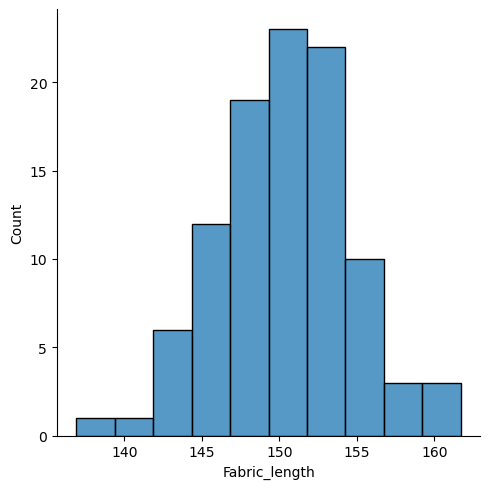

In [5]:
# Option2 Density
sns.displot(Fabric['Fabric_length'])
plt.show()

In [6]:
# Option3 Shiparo Test 
stats.shapiro(Fabric['Fabric_length'])

ShapiroResult(statistic=0.9908479452133179, pvalue=0.7328956723213196)

In [7]:
### select the statistical test & calculate p-vlaue
# 1 sample Z Test

In [8]:
Fabric['Fabric_length'].mean()

150.30599999999995

In [9]:
Z_cal=(150.30-150)/(4/np.sqrt(25))
print(Z_cal)

0.3750000000000142


In [10]:
stats.norm.cdf(Z_cal)

0.6461697666727291

In [11]:
#Step 5: Based on p value, Accept or Reject H0

P> Alpha

P High ---Null Fly

Do not Reject H0

# Bolt Diameter

In [12]:
bolt = pd.read_excel("Bolt%20diameter.xlsx")
print(bolt.head())

   Diameter
0     11.27
1     12.06
2     12.15
3      9.89
4     10.82


Step 1. Formulation of Ho,Ha

Ho : Mean = 10 
    
Ha : Mean != 10

Step 2: Level Of Significance alpha
alpha = 0.05

Step 3: Check for normality

In [13]:
bolt['Diameter'].skew()

-0.7964579633479307

In [14]:
### select the statistical test & calculate p-vlaue
# 1 sample Z Test

In [15]:
stats.ttest_1samp(bolt.Diameter, 10)

Ttest_1sampResult(statistic=5.754345479854947, pvalue=5.581958402822294e-07)

P< Alpha

P Low ---Null Go (Reject H0)

Do Reject H0

#The p-value (0.00000055819) is less than the significance level (0.05).
#Therefore, we reject the null hypothesis (H₀). 
#There is sufficient statistical evidence to conclude that the population mean 
#bolt diameter is significantly different from 10.

# Credit Card Promotion

Ho : Avg of purchases made by FIW <= Avg purchases made by SC=> default/current/no action
Ha : Avg of purchases made by FIW > Avg purchases made by SC=> take action

In [16]:
promotion = pd.read_excel("Promotion_Practice.xlsx")
promotion.head()

,InterestRateWaiver,StandardPromotion
0,1989.10,1272.25
1,1808.38,1250.38
2,1153.75,1474.78
3,1745.64,2064.89
4,1008.24,2030.87


Step 2: Level Of Significance alpha alpha = 0.05

alpha = 0.05

In [19]:
print(stats.shapiro(promotion.InterestRateWaiver))

ShapiroResult(statistic=0.8462002277374268, pvalue=0.000516781525220722)


In [20]:
print(stats.shapiro(promotion.StandardPromotion))

ShapiroResult(statistic=0.9615997076034546, pvalue=0.3401343524456024)


Variance Test-Levene Test

Ho: Variances are equal
H1:  Variances are not equal

In [22]:
stats.levene(promotion.InterestRateWaiver,promotion.StandardPromotion)

LeveneResult(statistic=0.5973410634979592, pvalue=0.4427327022581443)

 Select the statistical test & Caluculate the p-value

2 sample test for equal variance

In [24]:
stats.ttest_ind(promotion.InterestRateWaiver,promotion.StandardPromotion,equal_var=True)

Ttest_indResult(statistic=2.3587383950076948, pvalue=0.02172751716320693)

Conclusion:
- P-value = 0.0242
- Alpha = 0.05
- P < Alpha
- Reject H₀
There is a statistically significant difference between the average purchases
under the two promotions.

2 sample test for unequal variance

In [25]:
stats.ttest_ind(promotion.InterestRateWaiver,promotion.StandardPromotion,equal_var=False)

Ttest_indResult(statistic=2.3587383950076948, pvalue=0.021728113643240093)

# Contract Renewal

In [26]:

import pandas as pd
from scipy import stats

# Load Excel dataset
cof = pd.read_excel("Contract Renewal.xlsx")
cof.head()


,SupplierA,SupplierB,SupplierC
0,6.15,7.87,7.41
1,6.22,5.21,3.61
2,6.76,7.94,7.23
3,4.29,7.36,5.53
4,7.08,6.17,3.97


In [ ]:
### 2. Hypothesis Formulation
H₀: Average renewal times for all three suppliers are equal.

H₁: At least one supplier has a different average renewal time.

Alpha = 0.05

# 3. Check Normality – Shapiro-Wilk Test

In [28]:

print(stats.shapiro(cof.SupplierA))
print(stats.shapiro(cof.SupplierB))
print(stats.shapiro(cof.SupplierC))


ShapiroResult(statistic=0.9811882972717285, pvalue=0.8561992049217224)
ShapiroResult(statistic=0.9720214605331421, pvalue=0.5958425998687744)
ShapiroResult(statistic=0.9769771099090576, pvalue=0.7407621145248413)


In [29]:

# Check variance across all three suppliers
stats.levene(
    cof.SupplierA,
    cof.SupplierB,
    cof.SupplierC
)


LeveneResult(statistic=1.2215051213610362, pvalue=0.2997911290108367)

In [30]:

print(stats.levene(cof.SupplierA, cof.SupplierB))
print(stats.levene(cof.SupplierB, cof.SupplierC))
print(stats.levene(cof.SupplierA, cof.SupplierC))


LeveneResult(statistic=1.0370616863281625, pvalue=0.31273505031567134)
LeveneResult(statistic=2.5099021326514785, pvalue=0.1185708766649792)
LeveneResult(statistic=0.34479581048563823, pvalue=0.5593529651021858)


Select the statistical test & Calculate the p value

Anova Test (F-Test)

In [32]:
stats.f_oneway(cof.SupplierA, cof.SupplierB,cof.SupplierC)

F_onewayResult(statistic=4.244664295442282, pvalue=0.01742015284160785)

Based on the p value, Accept or Reject H0

P-value (0.01742) < Alpha (0.05)
- P < Alpha
- P Low → Null Go
- Reject H₀

# Foot Ball

1.Formulation Of H0,H1

Ho: Coach not to be fired(No Action)-No Difference

H1: Coach to be fired(Action)

Step 2: Level Of Significance alpha alpha = 0.05
    
Alpha = 0.05

Select the statistical test & Caluculate the p-value

1 Proportion Test

In [34]:
stats.binom_test(482, 2000, 0.25)

C:\Users\vasan\anaconda3\lib\site-packages\scipy\stats\_discrete_distns.py:78: RuntimeWarning: divide by zero encountered in _binom_pdf
  return _boost._binom_pdf(x, n, p)


0.3661511582182897

Conclusion
- P-value = 0.3662
- Alpha = 0.05
- P > Alpha
- Do not reject H₀

# Johny Talkers

In [35]:
df = pd.read_excel("JohnyTalkers.xlsx")
df.head()


,Person,Drinks
0,Adults,Did Not Purchase
1,Adults,Did Not Purchase
2,Adults,Did Not Purchase
3,Adults,Did Not Purchase
4,Adults,Did Not Purchase


In [36]:
df["Person"].value_counts()

Children    740
Adults      480
Name: Person, dtype: int64

In [37]:
df["Drinks"].value_counts()

Did Not Purchase    1010
Purchased            210
Name: Drinks, dtype: int64

In [40]:
#Crosstable
pd.crosstab(df["Person"],df["Drinks"],margins=True)

Drinks,Did Not Purchase,Purchased,All
Person,,,
Adults,422,58,480
Children,588,152,740
All,1010,210,1220


In [ ]:
1. Formulation of H₀ and H₁
Null Hypothesis (H₀):

Proportion of Adults ≥= Proportion of Children


Alternative Hypothesis (H₁):

Proportion of Adults <= Proportion of Children


These proportions refer to the percentage of adults and children who purchased drinks.
2. Select Level of Significance

alpha=0.05


3. Select the Statistical Test & Calculate the P-value
Statistical Test: Two-Proportion Z-Test

In [41]:

import numpy as np
from statsmodels.stats.proportion import proportions_ztest

count = np.array([58, 152])  # Adults and children purchasing drinks
nobs = np.array([480, 740])  # Total adults and children

proportions_ztest(count, nobs, alternative='two-sided')


(-3.8227247718795447, 0.00013198507287726183)

Z-statistic = -3.8227

P-value = 0.000132

Alpha = 0.05

4. Based on P-value, Accept or Reject H₀
- P < Alpha
- P Low → Null Go
- Reject H₀
- Evidence supports H₁: The adult purchase proportion is lower than the 
    children's purchase proportion.

# Bahaman

In [42]:
Bahaman = pd.read_excel("Bahaman.xlsx")
Bahaman.head()

,Defective,Country
0,0,India
1,0,India
2,0,India
3,0,India
4,0,India


In [43]:
count=pd.crosstab(Bahaman["Defective"],Bahaman["Country"])
count

Country,Bangladesh,China,India,Srilanka
Defective,,,,
0,183,179,175,178
1,17,21,25,22


#Select the Statistical Test & Calculate the P-value
Chisquare Test

# Chisquare Test

In [46]:
stats.chi2_contingency(count)

(1.7243932538050184,
 0.6315243037546223,
 3,
 array([[178.75, 178.75, 178.75, 178.75],
        [ 21.25,  21.25,  21.25,  21.25]]))

In [49]:
Chisquares_results= stats.chi2_contingency(count)
print('p-value:',Chisquares_results[1])

p-value: 0.6315243037546223


P > Alpha
- P High→ Null fly
- Accept H₀